# Module 2: Food, Beverage & Banquet Performance Analytics
**Institution:** Invertis University, Bareilly (Faculty of Computer Applications)  
**Project:** ITC Hotels: Revenue & Business Performance Analysis (BCA Final Year Capstone)  
**Project Team:** Jatin Sagar (BC2023727), Atul Kumar (BC2023590), Darshika Rathore (BC2023687), Muskan Saxena (BC2023061)  
**Project Guide:** Ms. Megha Saxena, Assistant Professor  
**Database:** MySQL 8.0 / SQLite 3NF Database (`itc_hotel_analytics.db`)

---
## 1. Executive Summary & Business Context
Culinary excellence is a cornerstone of ITC Hotels' identity, home to award-winning brands like **Bukhara, Dum Pukht, and Peshawri**. MICE (Meetings, Incentives, Conferences, and Exhibitions) and grand weddings held in halls like *The Grand Ballroom* and *Peacock Hall* generate crucial non-room revenue streams.

This notebook evaluates restaurant covers, dining plan profitability, beverage margins, and banquet event yield.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 6)

# Load via SQL from itc_hotel_analytics.db
db_path = '../ITC-Final-Dashboards/itc_hotel_analytics.db'
if os.path.exists(db_path):
    conn = sqlite3.connect(db_path)
    sql_query = """
    SELECT 
        f.booking_id,
        r.hotel_name,
        r.arrival_date,
        r.arrival_year,
        r.arrival_month,
        r.is_canceled,
        f.dining_plan,
        f.restaurant_outlet,
        f.dining_covers,
        f.food_revenue_inr,
        f.beverage_revenue_inr,
        f.total_fnb_revenue_inr,
        b.banquet_hall,
        b.event_type AS banquet_event_type,
        b.attendees AS banquet_attendees,
        b.banquet_revenue_inr,
        (f.total_fnb_revenue_inr + COALESCE(b.banquet_revenue_inr, 0)) AS combined_fnb_banquet_rev_inr
    FROM fnb_orders f
    JOIN reservations r ON f.booking_id = r.booking_id
    LEFT JOIN banquet_events b ON f.booking_id = b.booking_id
    """
    df_fnb = pd.read_sql_query(sql_query, conn)
    conn.close()
    print(f"✓ Successfully loaded {len(df_fnb):,} records via SQL query")
else:
    df_fnb = pd.read_csv('itc_fnb_banquet_performance.csv')
    print(f"✓ Loaded {len(df_fnb):,} records from CSV")

df_fnb.head()

✓ Successfully loaded 87,396 records via SQL query


,booking_id,hotel_name,arrival_date,arrival_year,arrival_month,is_canceled,dining_plan,restaurant_outlet,dining_covers,food_revenue_inr,beverage_revenue_inr,total_fnb_revenue_inr,banquet_hall,banquet_event_type,banquet_attendees,banquet_revenue_inr,combined_fnb_banquet_rev_inr
0,ITC-2015-000001,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast,Pan Asian,2,0.00,0.00,0.00,NaN,NaN,NaN,NaN,0.00
1,ITC-2015-000002,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast,West View,2,0.00,0.00,0.00,Rajputana Hall,Gala Dinner,280.0,552284.53,552284.53
2,ITC-2015-000003,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast,Pavilion,1,2608.54,690.74,3299.28,Peacock Hall,Wedding Reception,142.0,336742.42,340041.70
3,ITC-2015-000004,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast,West View,1,2451.84,480.50,2932.34,NaN,NaN,NaN,NaN,2932.34
4,ITC-2015-000005,ITC Grand Bharat (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast,West View,2,3132.05,759.24,3891.29,Rajputana Hall,Wedding Reception,240.0,593835.62,597726.91


## 2. F&B Executive Scorecard

In [2]:
valid_fnb = df_fnb[df_fnb['is_canceled'] == 0]
tot_fnb_cr = valid_fnb['total_fnb_revenue_inr'].sum() / 1e7
tot_food_cr = valid_fnb['food_revenue_inr'].sum() / 1e7
tot_bev_cr = valid_fnb['beverage_revenue_inr'].sum() / 1e7
tot_banq_cr = valid_fnb['banquet_revenue_inr'].sum() / 1e7
tot_combined_cr = valid_fnb['combined_fnb_banquet_rev_inr'].sum() / 1e7
total_covers = valid_fnb['dining_covers'].sum()

print("="*60)
print(f"ITC F&B AND BANQUET PERFORMANCE SCORECARD")
print("="*60)
print(f"Total Dining Covers Served: {total_covers:,}")
print(f"Food Revenue              : ₹ {tot_food_cr:,.2f} Crores")
print(f"Beverage Revenue          : ₹ {tot_bev_cr:,.2f} Crores")
print(f"Total Restaurant F&B Rev  : ₹ {tot_fnb_cr:,.2f} Crores")
print(f"Total Banquet Event Rev   : ₹ {tot_banq_cr:,.2f} Crores")
print(f"Combined F&B Portfolio Rev: ₹ {tot_combined_cr:,.2f} Crores")
print("="*60)

ITC F&B AND BANQUET PERFORMANCE SCORECARD
Total Dining Covers Served: 123,692
Food Revenue              : ₹ 19.10 Crores
Beverage Revenue          : ₹ 4.78 Crores
Total Restaurant F&B Rev  : ₹ 23.88 Crores
Total Banquet Event Rev   : ₹ 1,332.29 Crores
Combined F&B Portfolio Rev: ₹ 1,356.17 Crores


## 3. Signature Restaurant Outlet Revenue Contribution

,restaurant_outlet,total_covers,food_rev_cr,bev_rev_cr,total_rev_cr
0,West View,20755,3.225015,0.807437,4.032453
1,Peshawri,20800,3.207517,0.801172,4.008689
2,Bukhara,20552,3.180494,0.795082,3.975576
3,Pan Asian,20650,3.167624,0.793287,3.960911
4,Pavilion,20385,3.160757,0.790893,3.951651
5,Dum Pukht,20550,3.155099,0.789978,3.945077


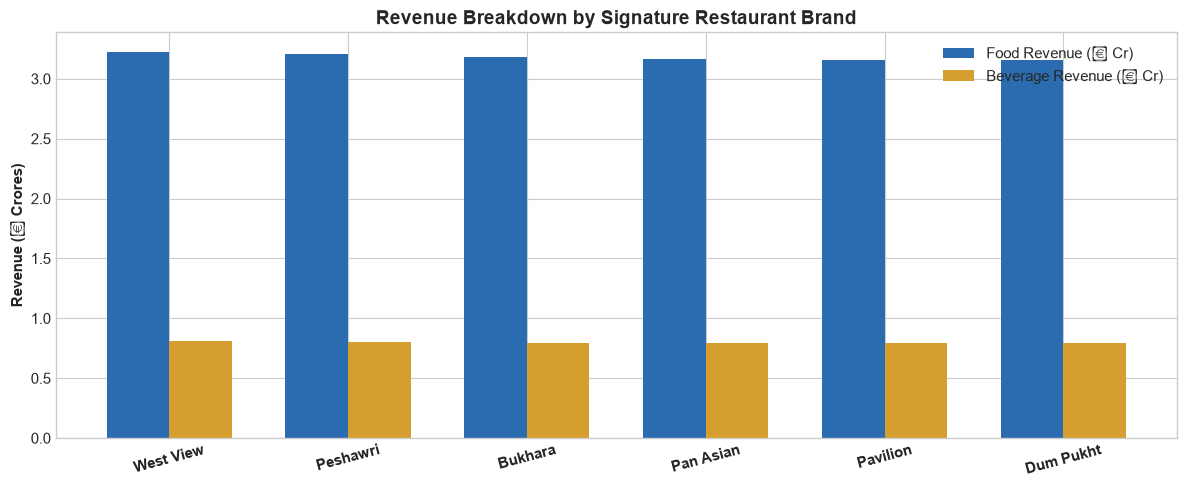

In [3]:
rest_perf = valid_fnb[valid_fnb['dining_covers'] > 0].groupby('restaurant_outlet').agg(
    total_covers=('dining_covers', 'sum'),
    food_rev_cr=('food_revenue_inr', lambda x: x.sum() / 1e7),
    bev_rev_cr=('beverage_revenue_inr', lambda x: x.sum() / 1e7),
    total_rev_cr=('total_fnb_revenue_inr', lambda x: x.sum() / 1e7)
).sort_values(by='total_rev_cr', ascending=False).reset_index()

display(rest_perf)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(rest_perf))
width = 0.35

ax.bar(x - width/2, rest_perf['food_rev_cr'], width, label='Food Revenue (₹ Cr)', color='#2B6CB0')
ax.bar(x + width/2, rest_perf['bev_rev_cr'], width, label='Beverage Revenue (₹ Cr)', color='#D69E2E')
ax.set_xticks(x)
ax.set_xticklabels(rest_perf['restaurant_outlet'], rotation=15, fontweight='bold')
ax.set_ylabel('Revenue (₹ Crores)', fontweight='bold')
ax.set_title('Revenue Breakdown by Signature Restaurant Brand', fontweight='bold', fontsize=14)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Banquet Event Analysis & MICE Contribution

,banquet_event_type,events_hosted,total_attendees,revenue_cr
0,Corporate Conference,10190,1642142.0,272.860738
1,Wedding Reception,10240,1627576.0,268.147428
2,Gala Dinner,10005,1610535.0,266.694353
3,Product Launch,10041,1597468.0,263.301289
4,Board Meeting,9985,1587513.0,261.285300


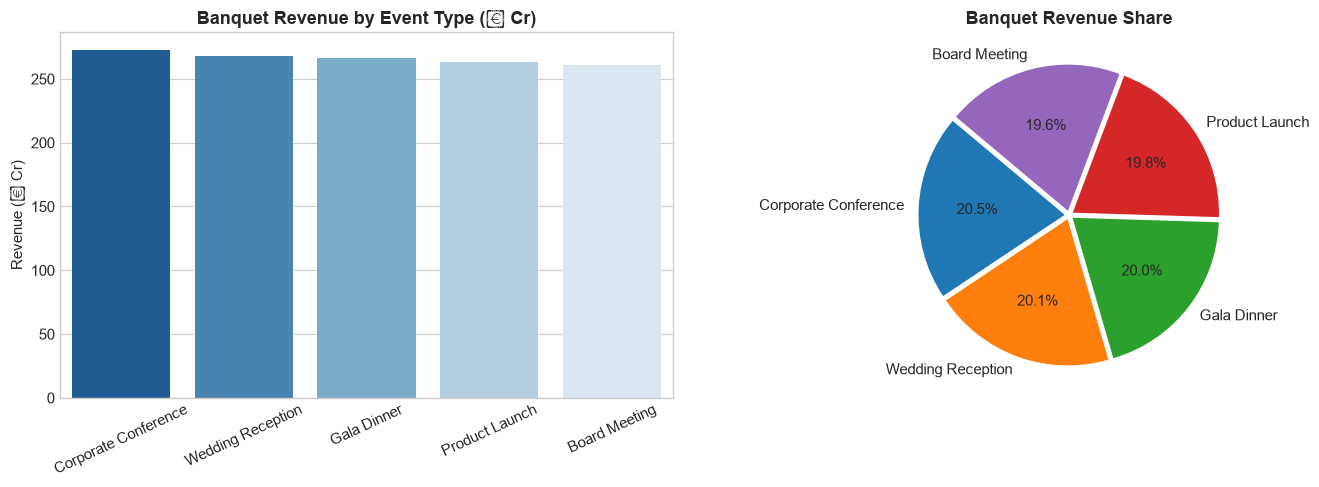

In [4]:
banq_data = valid_fnb[valid_fnb['banquet_event_type'].notna() & (valid_fnb['banquet_event_type'] != 'None')]
event_summary = banq_data.groupby('banquet_event_type').agg(
    events_hosted=('booking_id', 'count'),
    total_attendees=('banquet_attendees', 'sum'),
    revenue_cr=('banquet_revenue_inr', lambda x: x.sum() / 1e7)
).sort_values(by='revenue_cr', ascending=False).reset_index()

display(event_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=event_summary, x='banquet_event_type', y='revenue_cr', ax=axes[0], palette='Blues_r')
axes[0].set_title('Banquet Revenue by Event Type (₹ Cr)', fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Cr)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)

n_events = len(event_summary)
explode = [0.03] * n_events
axes[1].pie(event_summary['revenue_cr'], labels=event_summary['banquet_event_type'], 
            autopct='%1.1f%%', startangle=140, colors=sns.color_palette('tab10', n_events),
            explode=explode)
axes[1].set_title('Banquet Revenue Share', fontweight='bold')

plt.tight_layout()
plt.show()